In [97]:
import pandas as pd # run this before anything!!!
import matplotlib.pyplot as plt # run this before anything!!!
import numpy as np # run this before anything!!!


df = pd.read_csv("titanic.csv")
df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [98]:
df.dtypes

PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str
dtype: object

In [99]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [100]:
df["Age"].mean()

np.float64(29.69911764705882)

In [101]:
df["Age"] = df["Age"].fillna(int(df["Age"].mean()))

In [102]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [103]:
df["Age"].min()

np.float64(0.42)

In [104]:
df["Age"].max()

np.float64(80.0)

In [105]:
df["Survived"].value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

In [106]:
df["Pclass"].value_counts()

Pclass
3    491
1    216
2    184
Name: count, dtype: int64

In [107]:
df["Sex"].value_counts()

Sex
male      577
female    314
Name: count, dtype: int64

In [108]:
df[df["Survived"] == 1]["Sex"].value_counts()

Sex
female    233
male      109
Name: count, dtype: int64

In [109]:
df.groupby("Sex")["Survived"].sum()

Sex
female    233
male      109
Name: Survived, dtype: int64

In [110]:
df.groupby("Pclass")["Survived"].sum()

Pclass
1    136
2     87
3    119
Name: Survived, dtype: int64

In [111]:
df["Fare"].max()

np.float64(512.3292)

In [112]:
df["Embarked"].value_counts()

Embarked
S    644
C    168
Q     77
Name: count, dtype: int64

Text(0.5, 1.0, 'Stuff')

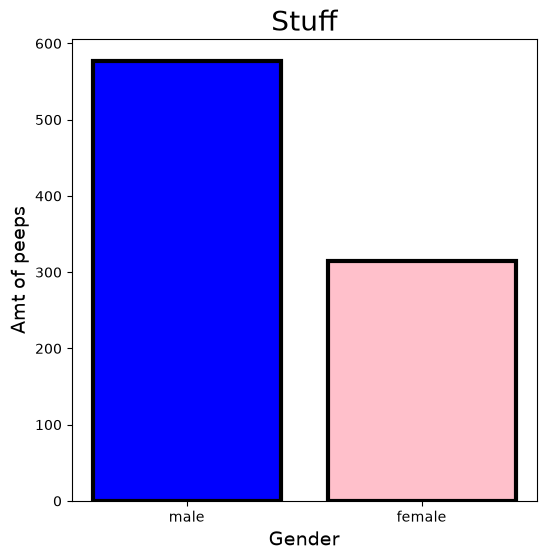

In [113]:
peeps = df["Sex"].value_counts()

plt.figure(figsize = (6, 6))
plt.bar(peeps.index, peeps.values, label = ["Male", "Female"],color = ["blue", "pink"], edgecolor = 'black', linewidth = 3)
plt.xlabel("Gender", fontsize = 14)
plt.ylabel("Amt of peeps", fontsize = 14)
plt.title("Stuff", fontsize = 20)

Text(0.5, 1.0, 'Stuff')

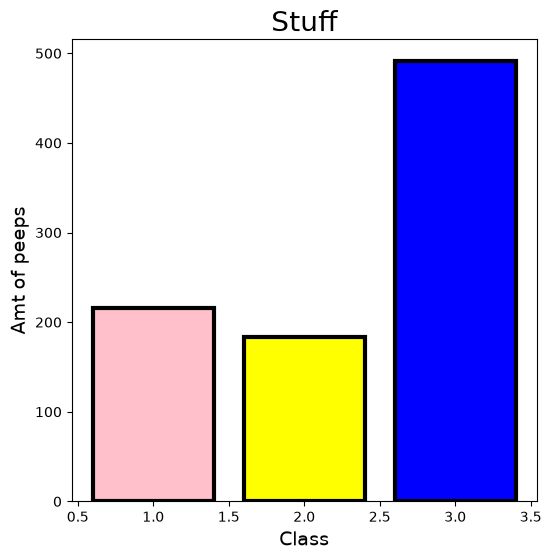

In [114]:
peeps = df["Pclass"].value_counts()

plt.figure(figsize = (6, 6))
plt.bar(peeps.index, peeps.values, label = ["1st", "2nd", "3rd"],color = ["blue", "pink", "yellow"], edgecolor = 'black', linewidth = 3)
plt.xlabel("Class", fontsize = 14)
plt.ylabel("Amt of peeps", fontsize = 14)
plt.title("Stuff", fontsize = 20)

(array([ 54.,  46., 177., 346., 118.,  70.,  45.,  24.,   9.,   2.]),
 array([ 0.42 ,  8.378, 16.336, 24.294, 32.252, 40.21 , 48.168, 56.126,
        64.084, 72.042, 80.   ]),
 <BarContainer object of 10 artists>)

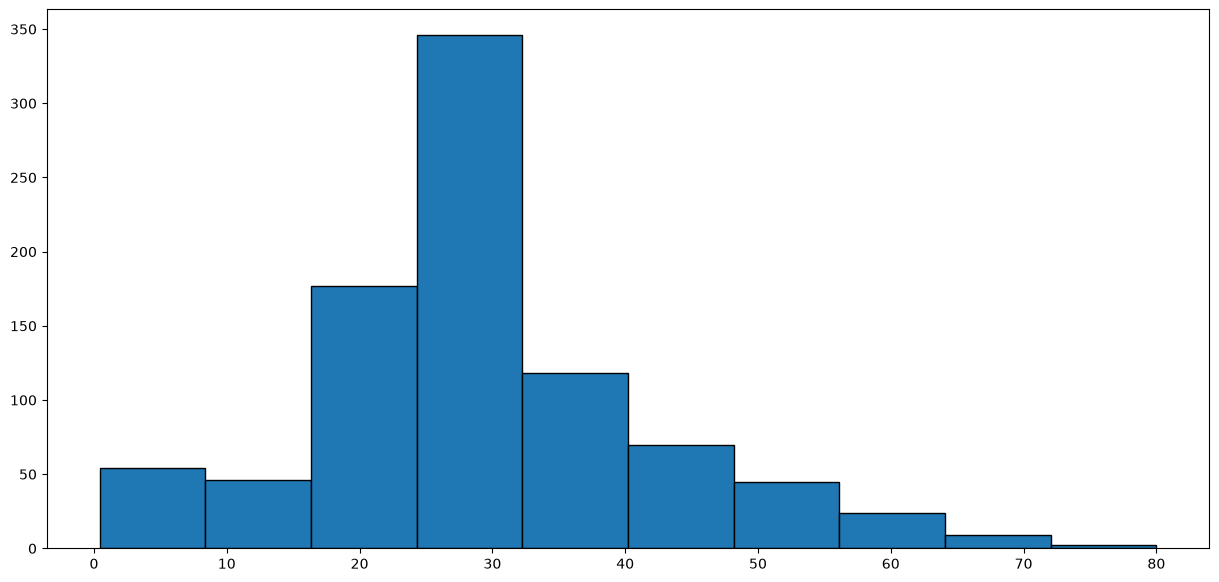

In [115]:

plt.figure(figsize = [15,7])
plt.hist(df["Age"], bins = 10, edgecolor = "black")

In [116]:
df[df["Age"] == 80][["Name", "Age", "Survived"]]

,Name,Age,Survived
630,"Barkworth, Mr. Algernon Henry Wilson",80.0,1


Text(0.5, 1.0, 'Survivals per class in the Titanic')

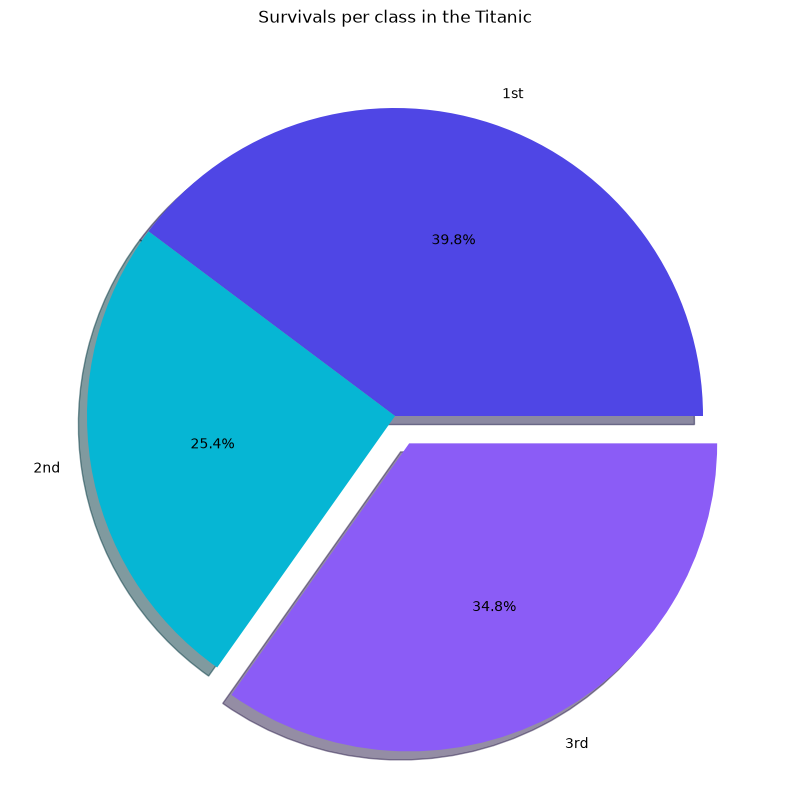

In [117]:
survivors = df[df["Survived"] == 1]
survivorclass = survivors["Pclass"].value_counts().sort_index()
labels = ["1st", "2nd", "3rd"]
survivorclass

explodes = (0,0,0.1)
colors = ["#4F46E5", "#06B6D4", "#8B5CF6"]

plt.figure(figsize = (10,10))
plt.pie(survivorclass, labels = labels, autopct = "%1.1f%%", colors = colors, explode = explodes, shadow = True)
plt.title("Survivals per class in the Titanic")

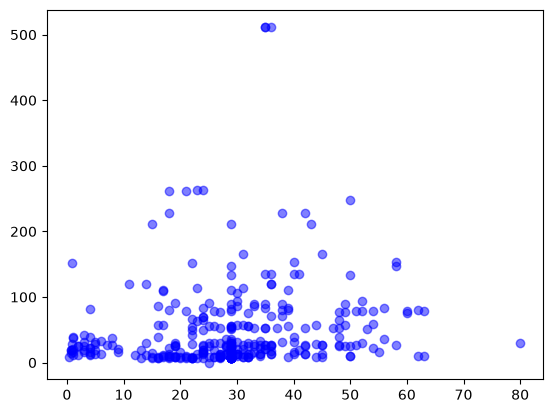

In [118]:
plt.scatter(survivors["Age"], survivors["Fare"], color = "blue", alpha = 0.5)

In [119]:
unalived = df[df["Survived"] == 0]

In [94]:
unalivedgender = unalived["Sex"].value_counts()

In [95]:
unalivedgender

Sex
male      468
female     81
Name: count, dtype: int64

In [121]:
survivedgender = survivors["Sex"].value_counts()

survivedgender

Sex
female    233
male      109
Name: count, dtype: int64

In [128]:
malecount = [survivedgender["male"], unalivedgender["male"]]
malecount

[np.int64(109), np.int64(468)]

In [129]:
femalecount = [survivedgender["female"], unalivedgender["female"]]
femalecount      

[np.int64(233), np.int64(81)]

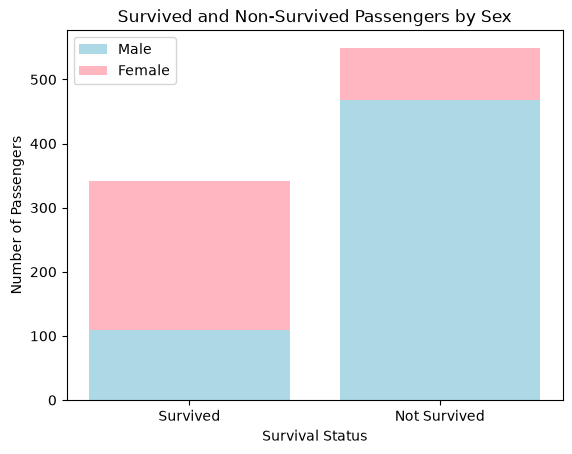

In [130]:
plt.bar(['Survived', 'Not Survived'], malecount, color='lightblue', label='Male')
plt.bar(['Survived', 'Not Survived'], femalecount, bottom=malecount, color='lightpink', label='Female')
plt.title('Survived and Non-Survived Passengers by Sex')
plt.xlabel('Survival Status')
plt.ylabel('Number of Passengers')
plt.legend()

In [131]:
survival_count = df["Survived"].value_counts()
survival_count

Survived
0    549
1    342
Name: count, dtype: int64

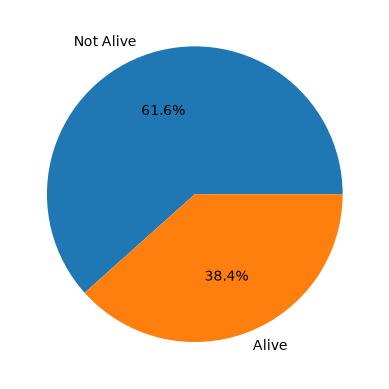

In [134]:
labels = ["Not Alive", "Alive"]

plt.pie(survival_count, labels = labels, autopct = "%1.1f%%")